# Nitrogen-based RDFs at 300 K

All three panels use the reduced nitrogen coordinate exported in one trajectory pass: anion central N--anion central N, cation ring-N midpoint--cation ring-N midpoint, and cation ring-N midpoint--anion central N. Coloured lines are simulation RDFs; black dashed lines are the supplied matching reference RDFs.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

start = Path.cwd().resolve()
repo = next(path for path in (start, *start.parents) if (path / '02_rdf/data/nitrogen_rdfs_300K.csv').is_file())
chapter = repo / '02_rdf'
rdf = pd.read_csv(chapter / 'data/nitrogen_rdfs_300K.csv')
references = {}
for pair, filename in {'anion_anion': 'anion-anion.csv', 'cation_cation': 'cation-cation.csv', 'cation_anion': 'cation-anion.csv'}.items():
    ref = pd.read_csv(chapter / 'reference_data' / filename)
    ref.columns = [column.strip() for column in ref.columns]
    references[pair] = ref
rdf.groupby(['pair', 'force_field']).size()

/home/akryachkova/ams2025.106/bin/python3.8/lib/python3.8/site-packages/mpl_toolkits/__init__.py:2: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  __import__('pkg_resources').declare_namespace(__name__)
/home/akryachkova/.conda/envs/so3lr312/lib/python3.12/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


pair           force_field
anion_anion    APPLE&P        751
               CL&P           751
               CL&P-scaled    751
               SO3LR          751
cation_anion   APPLE&P        751
               CL&P           751
               CL&P-scaled    751
               SO3LR          751
cation_cation  APPLE&P        751
               CL&P           751
               CL&P-scaled    751
               SO3LR          751
dtype: int64

Wrote /gpfs/home5/akryachkova/emimntf2-paper-repro/02_rdf/figures/nitrogen_rdfs_300K.png


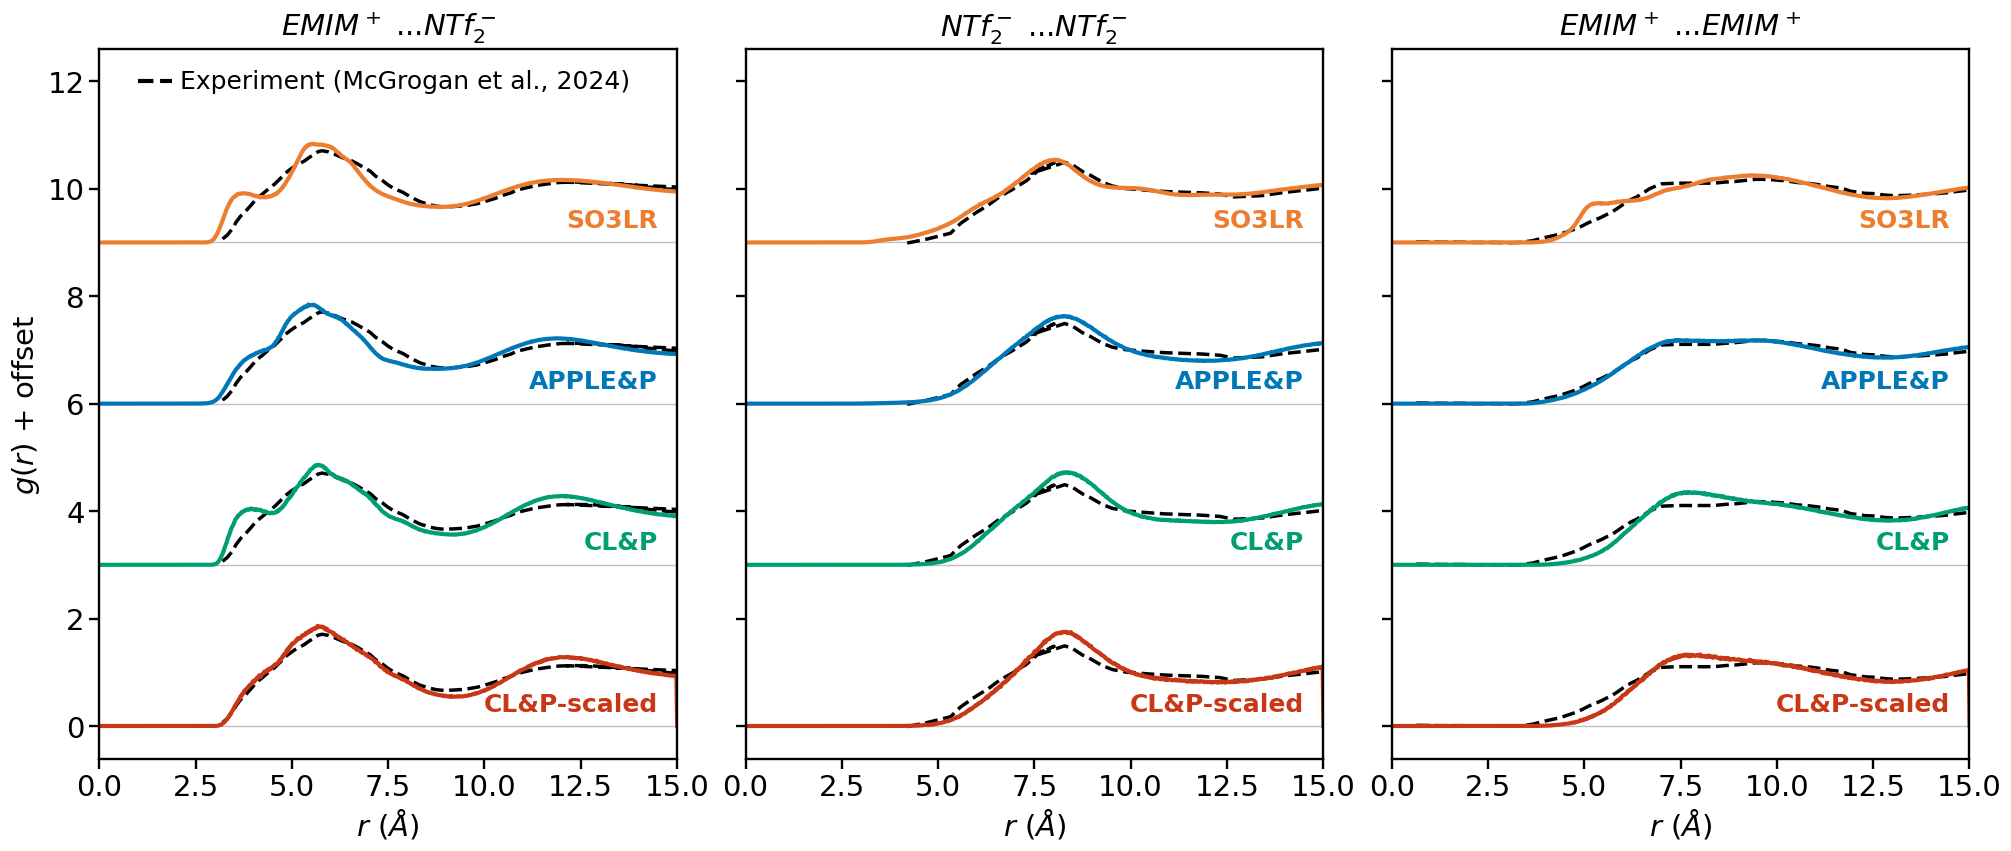

In [10]:
styles = {
   'SO3LR': ('#ed7d31', 9.0),
    'APPLE&P': ('#0078b8', 6.0),
    
    'CL&P': ('#009e73', 3.0),
    'CL&P-scaled': ('#c83817', 0.0),
}
panels = [
    ('cation_anion', '$EMIM^+$ ...$NTf_2^-$'),
    ('anion_anion', '$NTf_2^-$ ...$NTf_2^-$'),
    ('cation_cation', '$EMIM^+$ ...$EMIM^+$')
    
]
fig, axes = plt.subplots(1, 3, figsize=(20.0, 8.4), sharey=True, constrained_layout=True)
for ax, (pair, title) in zip(axes, panels):
    ref = references[pair]
    for force_field, (colour, offset) in styles.items():
        values = rdf.loc[rdf.pair.eq(pair) & rdf.force_field.eq(force_field)].sort_values('distance_A')
        assert not values.empty, f'Missing {pair}: {force_field}'
        ax.axhline(offset, color='0.75', linewidth=1.0, zorder=0)
        ax.plot(ref.x, ref.y + offset, color='black', linestyle='--', linewidth=2.5, zorder=1)
        ax.plot(values.distance_A, values.g_r + offset, color=colour, linewidth=3, zorder=2)
        ax.text(14.5, offset + 0.28, force_field, color=colour, fontsize=18, fontweight='bold', ha='right')
    ax.set_title(title, fontsize=21, pad=10)
    ax.set_xlim(0, 15)
    ax.set_xlabel(r'$r$ ($\AA$)', fontsize=21)
    ax.tick_params(axis='both', which='major', labelsize=21, width=1.7, length=7)
    for spine in ax.spines.values():
        spine.set_linewidth(1.7)
axes[0].set_ylabel(r'$g(r)$ + offset', fontsize=21)
axes[0].plot([1.0, 1.9], [12.0, 12.0], color='black', linestyle='--', linewidth=3)
axes[0].text(2.1, 11.86, 'Experiment (McGrogan et al., 2024)', fontsize=18)
output = chapter / 'figures/nitrogen_rdfs_300K.png'
fig.savefig(output, dpi=300, facecolor='white', bbox_inches='tight')
print(f'Wrote {output}')
plt.show()